# Étape 1 — Générer le dataset : série temporelle `s = sin(x)`

**Activité pratique N°4 — Architecture Transformer**

Objectif : créer une série temporelle de **200 valeurs de `sin(x)` pour `x ∈ [0, 20]`**, puis la découper en
**petites séquences de 10 valeurs**. Chaque séquence sert à prédire la valeur suivante :

```
X = [ [s0, s1, ..., s9], [s1, s2, ..., s10], [s2, ..., s11], ... ]
Y = [   s10,               s11,                s12,           ... ]
```

Ce dataset est réutilisé par les modèles RNN (étape 2), LSTM (étape 3) et Transformer (étape 4).

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 1. Générer 200 valeurs entre 0 et 20

In [2]:
periode = torch.linspace(0, 20, 200)   # 200 valeurs régulièrement espacées
serie = torch.sin(periode)             # s = sin(x)

print("Forme de la série :", serie.shape)
print("5 premières valeurs :", serie[:5])

Forme de la série : torch.Size([200])
5 premières valeurs : tensor([0.0000, 0.1003, 0.1997, 0.2970, 0.3913])


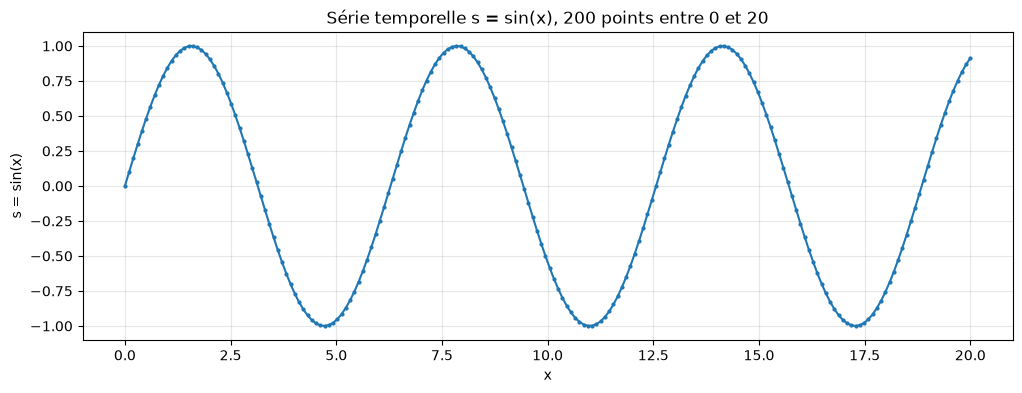

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(periode, serie, marker=".", markersize=4)
plt.title("Série temporelle s = sin(x), 200 points entre 0 et 20")
plt.xlabel("x")
plt.ylabel("s = sin(x)")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Ranger le dataset en séquences de dimension 10 (fenêtre glissante)

In [4]:
longueur_sequence = 10

X = torch.stack([serie[i:i + longueur_sequence]
                 for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence]
                 for i in range(len(serie) - longueur_sequence)])

print("X :", X.shape, "  y :", y.shape)   # (190, 10) et (190,)

X : torch.Size([190, 10])   y : torch.Size([190])


Vérifions que la cible de chaque séquence est bien la valeur **immédiatement suivante** :

In [5]:
for k in range(3):
    print(f"X[{k}] = s{k}..s{k+9}  ->  y[{k}] = s{k+10} = {y[k]:.4f}  (attendu {serie[k+10]:.4f})")

assert torch.equal(X[1, :-1], X[0, 1:]), "les fenêtres doivent se décaler d'un pas"
assert torch.equal(y, serie[longueur_sequence:]), "la cible doit être la valeur suivante"
print("\nOK : fenêtres glissantes correctes")

X[0] = s0..s9  ->  y[0] = s10 = 0.8442  (attendu 0.8442)
X[1] = s1..s10  ->  y[1] = s11 = 0.8937  (attendu 0.8937)
X[2] = s2..s11  ->  y[2] = s12 = 0.9342  (attendu 0.9342)

OK : fenêtres glissantes correctes


## 3. Adapter les dimensions pour PyTorch et séparer train / test

Les couches récurrentes et le Transformer (avec `batch_first=True`) attendent
`(nombre de séquences, longueur, variables par instant)` → `(190, 10, 1)`.

Le découpage est **chronologique** (pas de mélange) : on apprend sur le début de la courbe et on teste sur la fin.

In [6]:
X = X.unsqueeze(-1)   # (190, 10, 1)
y = y.unsqueeze(-1)   # (190, 1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X_train :", X_train.shape, " y_train :", y_train.shape)
print("X_test  :", X_test.shape, "  y_test  :", y_test.shape)

X_train : torch.Size([150, 10, 1])  y_train : torch.Size([150, 1])
X_test  : torch.Size([40, 10, 1])   y_test  : torch.Size([40, 1])


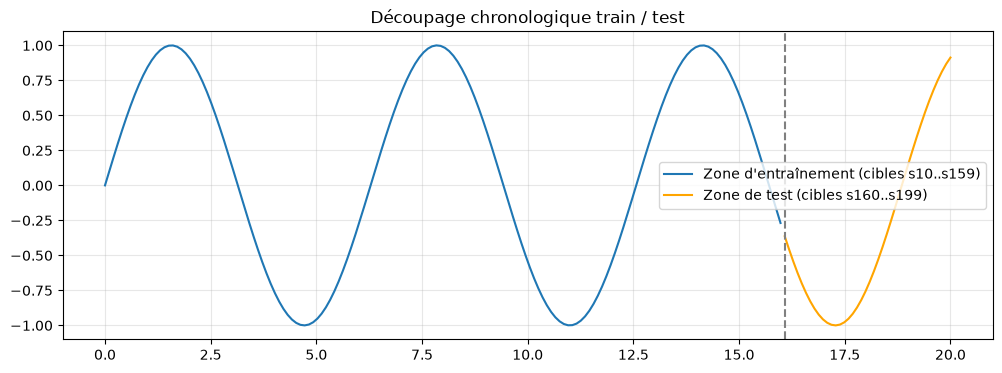

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(periode[:160], serie[:160], label="Zone d'entraînement (cibles s10..s159)")
plt.plot(periode[160:], serie[160:], label="Zone de test (cibles s160..s199)", color="orange")
plt.axvline(periode[160], color="gray", linestyle="--")
plt.title("Découpage chronologique train / test")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Résumé

| Tenseur | Forme | Contenu |
|---|---|---|
| `X` | `(190, 10, 1)` | 190 séquences de 10 valeurs |
| `y` | `(190, 1)` | la valeur suivante de chaque séquence |
| `X_train`, `y_train` | `(150, 10, 1)`, `(150, 1)` | 150 premiers exemples |
| `X_test`, `y_test` | `(40, 10, 1)`, `(40, 1)` | 40 derniers exemples |

➡️ Étape suivante : `02_rnn.ipynb`